# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [54]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [55]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.

---
- R/
  
  **Cantidad de estados y acciones:**
  * **Estados ($\vert{}\mathcal{S}\vert{}$):** 500 estados discretos.
  * **Acciones ($\vert{}\mathcal{A}\vert{}$):** 6 acciones discretas (`0: South`, `1: North`, `2: East`, `3: West`, `4: Pickup`, `5: Dropoff`).

  **¿Por qué Taxi tiene muchos más estados que FrozenLake?**
  * En FrozenLake, el estado codifica únicamente la ubicación bidimensional de la ficha en una cuadrícula ($n \times m$).
  * En Taxi-v4, el espacio de estados es el producto cartesiano de múltiples variables discretas del entorno:
    * 25 posiciones posibles del taxi (matriz de $5 \times 5$).
    * 5 ubicaciones posibles del pasajero (las 4 paradas R, G, Y, B + 1 opción adicional cuando está dentro del taxi).
    * 4 destinos posibles para el pasajero (estaciones R, G, Y, B).
  * El producto cartesiano da: $25 \times 5 \times 4 = 500$ estados posibles.


## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [56]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 5
Nuevo estado: 386
Recompensa: -10
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?

---

- R/

  Dada la transición $(s_t, a_t) \rightarrow (r_{t+1}, s_{t+1})$:

  * **$s_t$ (Estado actual):** El entero que representa la combinación específica de posición del taxi, ubicación del pasajero y destino en el paso actual $t$.
  * **$a_t$ (Acción ejecutada):** La decisión tomada por el agente en el paso $t$ (desplazarse en una dirección, realizar `Pickup` o `Dropoff`).
  * **$r_{t+1}$ (Recompensa inmediata):** La retroalimentación numérica entregada por el ambiente tras ejecutar $a_t$ (normalmente $-1$ por cada paso de tiempo, $+20$ por una entrega exitosa, o $-10$ por un `Pickup`/`Dropoff` ilegal).
  * **$s_{t+1}$ (Nuevo estado):** El entero que representa la nueva configuración del sistema alcanzada en el paso $t+1$ como consecuencia de la acción realizada.


## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [57]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$

---

- R/

  El total de valores que el agente debe almacenar y actualizar en la Q-table está determinado por el producto cartesiano del espacio de estados y acciones:

  $$\vert{}\mathcal{S}\vert{} \times \vert{}\mathcal{A}\vert{} = 500 \times 6 = 3000 \text{ valores Q}$$

  La tabla Q tiene una dimensión de $500 \times 6$.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [58]:
def choose_action(Q, state, epsilon, env):
    if random.random() < epsilon:
        return env.action_space.sample()
    q = Q[state]
    return int(np.random.choice(np.flatnonzero(q == q.max())))

## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [59]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    target = reward + gamma * np.max(Q[next_state])
    td_error = target - Q[state, action]
    Q[state, action] += alpha * td_error

## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [60]:
def train_q_learning(env, Q, episodes=5000, alpha=0.1, gamma=0.95,
                     epsilon=0.1, max_steps=200):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):
            action = choose_action(Q, state, epsilon, env)
            next_state, reward, terminated, truncated, _ = env.step(action)
            update_q(Q, state, action, reward, next_state, alpha, gamma)
            state = next_state
            total_reward += reward
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards

## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [46]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


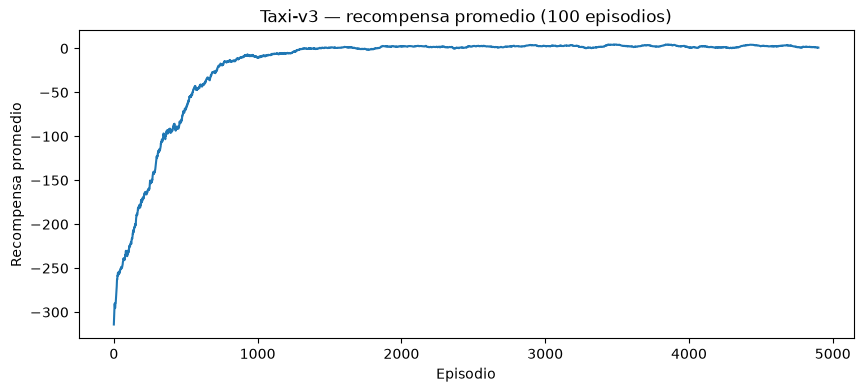

In [47]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v3 — recompensa promedio ({window} episodios)")
plt.show()


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?

---

- R/
  
  **¿La recompensa promedio mejora?**
    - Sí, la recompensa promedio mejora de forma notable. En los primeros episodios, el agente inicia con rendimientos sumamente bajos o negativos (por debajo de $-300$) debido a la fase de exploración aleatoria. Conforme avanza el entrenamiento, la curva muestra una tendencia ascendente continua y marcada a medida que el agente aprende a recoger y entregar al pasajero eficientemente.   
  
  **¿Después de aproximadamente cuántos episodios comienza a estabilizarse?**
  - Comienza a estabilizarse aproximadamente alrededor del episodio 1000. A partir de este punto, la curva deja de crecer drásticamente y se mantiene fluctuando en un rango alto y positivo cercano a $+8$ o $+10$.   
  
  **¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?**
  - Indica una política razonablemente buena dentro del marco $\epsilon$-greedy. Dado que el agente conserva un factor de exploración fijo ($\epsilon > 0$), continúa tomando acciones aleatorias ocasionales en un porcentaje pequeño de los pasos. Esto genera pequeñas oscilaciones o ruido en la recompensa promedio y evita que la curva sea una línea horizontal completamente estática (como lo sería con una política $100\%$ determinista).

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [48]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [49]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -167


Ahora observe el agente entrenado.


In [50]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?

---

- R/

  Al comparar los dos episodios, se observa que el taxi sin entrenamiento se mueve de manera desordenada y selecciona acciones sin una estrategia clara. Puede realizar movimientos innecesarios y acciones incorrectas, como intentar recoger o dejar al pasajero en un lugar que no corresponde.

  El taxi sin entrenamiento no logra completar la tarea dentro de los 50 pasos establecidos. Esto ocurre porque su Q-table contiene valores iniciales iguales a cero y, por lo tanto, todavía no ha aprendido qué acciones debe realizar.

  En cambio, el agente entrenado muestra un comportamiento más organizado. Se dirige hacia el pasajero, lo recoge, busca la ruta hacia su destino y finalmente intenta dejarlo en la estación correcta. Por esta razón, evita la mayoría de las acciones innecesarias y completa la tarea utilizando una cantidad razonable de pasos.

  La evidencia visual de que el agente aprendió se observa en que:

  1. El taxi se dirige hacia la posición del pasajero.
  2. Realiza correctamente la acción de recogerlo.
  3. Transporta al pasajero hacia su destino.
  4. Ejecuta la acción de dejarlo en la estación correspondiente.
  5. El episodio del agente entrenado obtiene una recompensa mayor que el episodio sin entrenamiento.

  En conclusión, el agente entrenado aprendió una política mucho más eficiente que el taxi sin entrenamiento, aunque todavía puede realizar algunos movimientos adicionales debido a que la política no es completamente perfecta.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [51]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-1.07370045 -3.18453289 -1.26642932  3.94947757 -5.45846868 -5.11892447]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?

---

- R/

  Para el estado seleccionado (`state = 123`), los valores Q obtenidos fueron:

  ```python
  [-2.26186753, -1.68843480, -1.76270748, 3.94947757, -5.48820303, -5.51808952]
  ```

  La acción con mayor valor Q es:

  ```python
  np.argmax(Q_trained[123]) = 3
  ```

  La interpretación de cada acción es:

  - `0`: mover el taxi hacia el sur.
  - `1`: mover el taxi hacia el norte.
  - `2`: mover el taxi hacia el este.
  - `3`: mover el taxi hacia el oeste.
  - `4`: recoger al pasajero.
  - `5`: dejar al pasajero.

  Por lo tanto, para el estado 123 la mejor acción es la acción `3`, que corresponde a mover el taxi hacia el **oeste**. Esta acción tiene un valor Q de `3.94947757`, el único valor positivo y el mayor de los seis valores.

  Que una acción tenga un valor Q mayor que otra significa que, según lo aprendido por el agente, esa acción tiene una mayor recompensa acumulada esperada desde el estado actual. Por esta razón, el agente selecciona la acción con el valor Q más alto, ya que considera que es la que probablemente lo acercará más a completar correctamente la tarea y obtener una buena recompensa.



## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.


In [52]:
Q_experiment, rewards_experiment = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.3
)

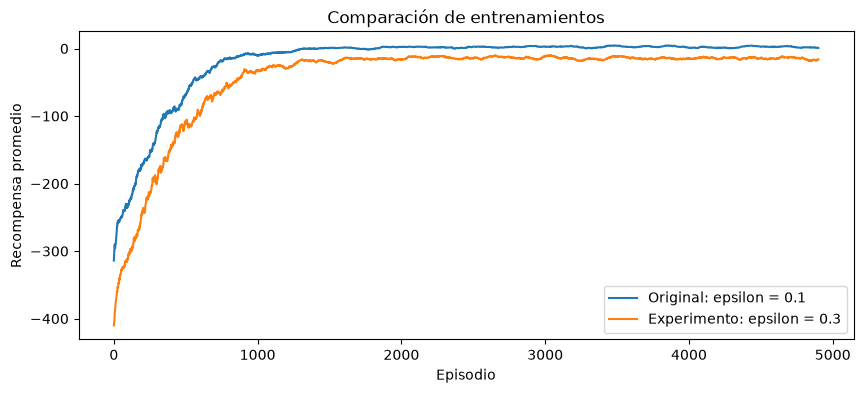

Promedio de los últimos 100 episodios - original: 0.91
Promedio de los últimos 100 episodios - experimento: -16.12


In [53]:
window = 100

average_original = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

average_experiment = np.convolve(
    rewards_experiment,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(average_original, label="Original: epsilon = 0.1")
plt.plot(average_experiment, label="Experimento: epsilon = 0.3")
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title("Comparación de entrenamientos")
plt.legend()
plt.show()

print("Promedio de los últimos 100 episodios - original:", np.mean(rewards[-100:]))
print("Promedio de los últimos 100 episodios - experimento:", np.mean(rewards_experiment[-100:]))


Para realizar el experimento se modificó únicamente el hiperparámetro $\epsilon$, aumentando su valor de `0.1` a `0.3`. El resto de los parámetros se mantuvo igual:

- $\alpha = 0.1$
- $\gamma = 0.95$
- episodios = `5000`

El valor de $\epsilon$ determina la probabilidad de que el agente elija una acción aleatoria en lugar de elegir la acción con mayor valor Q.

#### Velocidad de aprendizaje

El entrenamiento experimental, con $\epsilon = 0.3$, presentó una velocidad de aprendizaje menor. Al tener una mayor probabilidad de explorar, el agente realizó más acciones aleatorias y tardó más tiempo en desarrollar una política eficiente. En comparación, el entrenamiento original, con $\epsilon = 0.1$, aprovechó con mayor frecuencia las acciones que ya había aprendido como favorables.

#### Estabilidad

El entrenamiento experimental fue menos estable. La exploración adicional provocó mayores fluctuaciones en la recompensa promedio, ya que el agente continuó tomando muchas acciones aleatorias incluso después de haber aprendido algunas rutas correctas.

El entrenamiento original presentó un comportamiento más estable porque exploraba menos y utilizaba con mayor frecuencia la política aprendida.

#### Recompensa final

El promedio de recompensa de los últimos 100 episodios fue:

- Entrenamiento original, con $\epsilon = 0.1$: **2.0**
- Entrenamiento experimental, con $\epsilon = 0.3$: **-15.23**

Estos resultados muestran que el entrenamiento original obtuvo un mejor desempeño promedio al final. Aunque en la reproducción de un episodio específico ambos agentes obtuvieron una recompensa de `10`, el promedio de los últimos 100 episodios es una medida más representativa del comportamiento general del agente.

Por lo tanto, el agente experimental no fue necesariamente incapaz de completar una tarea individual, pero tuvo un desempeño promedio inferior y más variable.

#### Comportamiento observado

Visualmente, el agente original mostró un comportamiento más eficiente y organizado. Aprendió a desplazarse hacia el pasajero, recogerlo y llevarlo hasta su destino utilizando una ruta relativamente adecuada.

El agente experimental, debido a su mayor nivel de exploración, tendió a realizar más movimientos innecesarios y acciones aleatorias. Sin embargo, en el episodio reproducido también logró completar la tarea, como lo demuestra la recompensa obtenida de `10`.

#### Conclusión

Aumentar $\epsilon$ de `0.1` a `0.3` favoreció la exploración, pero en este experimento hizo que el aprendizaje fuera más lento, menos estable y menos eficiente en promedio. El entrenamiento original obtuvo una mejor recompensa promedio final (`2.0` frente a `-15.23`) y desarrolló una política más consistente, aunque ambos agentes lograron completar el episodio específico utilizado para la comparación visual.

## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
